# BÁO CÁO MILESTONE 3: REFERENCE MATCHING PIPELINE
## Chuyên đề: Auto-Labeling & Feature Engineering
**Người thực hiện:** Hoàng (Nhóm 11 - NMKHDL)  
**Mục tiêu:** Xây dựng pipeline gán nhãn tự động (Auto-Labeling) có độ tin cậy cao và bộ kỹ nghệ đặc trưng toàn diện (24 đặc trưng thuộc 6 nhóm) nhằm phục vụ mô hình học máy ghép nối mục trích dẫn BibTeX (Milestone 2) với siêu dữ liệu bài báo tham chiếu arXiv (Milestone 1 - Semantic Scholar API), đánh giá bằng chỉ số **MRR@5**.


## 1. Tổng quan & Khung bài toán (Problem Framing)

### 1.1. Không gian ứng viên (Candidate Space)
Trong mỗi ấn phẩm khoa học (publication) chứa $m$ mục BibTeX trích dẫn và $n$ bài báo tham chiếu cào được từ Semantic Scholar có arXiv ID:
- Không gian ứng viên tạo thành ma trận nhị phân kích thước $m \times n$.
- Mỗi ô $(i, j)$ mang nhãn dương (1 - **Positive / Match**) nếu mục BibTeX $i$ ứng với bài báo tham chiếu $j$, ngược lại mang nhãn âm (0 - **Negative / Non-match**).
- Với mỗi mục BibTeX, chỉ có tối đa một tham chiếu đúng (one-to-one mapping). Nếu mục BibTeX không tương ứng với bài arXiv nào trong $n$ bài tham chiếu thì toàn bộ hàng mang giá trị 0 (all-negative row).

### 1.2. Định dạng bài toán Học Máy (Learning to Rank / Binary Classification)
- **Đầu vào:** Mỗi cặp ứng viên $(BibTeX_i, Reference_j)$ được biểu diễn bằng một vector đặc trưng đa chiều $x_{ij} \in \mathbb{R}^{24}$ thuộc 6 nhóm đặc trưng.
- **Mục tiêu:** Mô hình học máy dự đoán xác suất $P(y_{ij} = 1 \mid x_{ij})$.
- **Đánh giá:** Với mỗi mục BibTeX $i$, sắp xếp các ứng viên $j$ theo xác suất giảm dần để lấy top 5 ứng viên ($cand_1 \dots cand_5$), tính chỉ số **MRR@5**:
$$\text{MRR@5} = \frac{1}{|Q|} \sum_{i=1}^{|Q|} \frac{1}{\text{rank}_i}$$


## 2. Phương pháp Gán nhãn Tự động (Auto-Labeling Pipeline)

Theo đặc tả của Milestone 3:
- Pool gán nhãn tự động chiếm ít nhất **10%** số publication ngoài tập thủ công (và tối thiểu $2k = 8$ publications với nhóm 4 người).
- Thuật toán gán nhãn tự động phải gán nhãn cho **toàn bộ** các mục BibTeX trong publication được chọn.

### 2.1. Các quy tắc Heuristics có độ chuẩn xác cao (High-Precision Rules)
1. **Rule 1 - Direct arXiv ID Match (Độ tin cậy tuyệt đối 1.0):** Trích xuất định danh arXiv qua biểu thức chính quy (Regex) từ các trường `eprint`, `url`, `note` của BibTeX và so sánh trực tiếp với `ref_arxiv_id`.
2. **Rule 2 - Exact Normalized Title + Metadata Verification (Độ tin cậy 0.98):** Chuẩn hóa tiêu đề (loại bỏ cú pháp LaTeX, dấu câu, đưa về chữ thường). Nếu tiêu đề trùng khớp hoàn toàn và có ít nhất 1 tác giả trùng hoặc năm xuất bản lệch không quá 1 năm.
3. **Rule 3 - Fuzzy Title Similarity & Margin Verification (Độ tin cậy 0.90 - 0.95):** Dùng `Token Sort Ratio` $\ge 90\%$. Đồng thời ứng viên đứng đầu phải vượt trội ứng viên thứ hai một khoảng cách an toàn (margin $\ge 0.10$) để tránh nhầm lẫn giữa các bài cùng chủ đề.
4. **Trường hợp âm tính (All-negative row):** Nếu không có ứng viên nào vượt qua các ngưỡng trên, mục BibTeX được gán nhãn `None`.


In [1]:
import json
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if "display" not in globals():
    try:
        from IPython.display import display
    except ImportError:
        display = print

plt.rcParams.update({
    "figure.autolayout": True,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

# Xác định đường dẫn thư mục gốc dự án
project_root = Path.cwd().parent if Path.cwd().name == "reports" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
manual_dir = project_root / "data" / "manual_labeling"
matching_dir = project_root / "data" / "matching"
sources_manual = project_root / "sourcesManual20"

print(f"Project root : {project_root}")
print(f"Data matching: {matching_dir.relative_to(project_root)}")
print(f"Sources manual: {sources_manual.relative_to(project_root)}")


Project root : C:\arxiv_project\NMKHDL_Nhom11
Data matching: data\matching
Sources manual: sourcesManual20


In [2]:
from src.model.data_cleaning import collect_bibtex_tables, flatten_references_json, clean_references_table, read_table
from src.model.auto_labeler import run_auto_labeling_pipeline, validate_auto_labels
from src.model.modeling import normalize_labels
from src.model.run_matching import publication_key

# 1. Tải dữ liệu thực tế từ 20 bài báo manual pool
bibtex_manual = collect_bibtex_tables(sources_manual)
bibtex_manual["arxiv_id"] = bibtex_manual["arxiv_id"].map(publication_key)

raw_refs_manual = flatten_references_json(sources_manual)
refs_manual = clean_references_table(raw_refs_manual)

# 2. Tải nhãn thủ công (Ground Truth) do nhóm thực hiện trên 20 bài báo
manual_labels = normalize_labels(read_table(manual_dir / "manual_labels.csv"), default_source="manual")
manual_labels["arxiv_id"] = manual_labels["arxiv_id"].map(publication_key)
manual_pubs = sorted(manual_labels["arxiv_id"].unique())

print(f"Số ấn phẩm trong tập manual : {len(manual_pubs)}")
print(f"Số mục trích dẫn BibTeX     : {len(manual_labels):,}")

# 3. Chạy pipeline Auto-Labeling trên chính 20 bài manual để kiểm tra độ tin cậy
auto_on_manual = run_auto_labeling_pipeline(bibtex_manual, refs_manual, target_publication_ids=manual_pubs)

# 4. Kiểm định chất lượng của Auto-Labeler so với nhãn tay
validation_results = validate_auto_labels(auto_on_manual, manual_labels)

val_display_df = pd.DataFrame([
    {"Chỉ số kiểm định Auto Labeler (trên 20 bài Manual)": "Số mục trích dẫn đối sánh (entries_compared)", "Giá trị": f"{validation_results['entries_compared']:,}"},
    {"Chỉ số kiểm định Auto Labeler (trên 20 bài Manual)": "Số cặp Auto-Labeler tìm thấy (auto_matches)", "Giá trị": f"{validation_results['auto_matches']:,}"},
    {"Chỉ số kiểm định Auto Labeler (trên 20 bài Manual)": "Số cặp Nhãn tay xác nhận (manual_matches)", "Giá trị": f"{validation_results['manual_matches']:,}"},
    {"Chỉ số kiểm định Auto Labeler (trên 20 bài Manual)": "Độ chính xác (Precision)", "Giá trị": f"{float(validation_results['precision']) * 100:.2f}%"},
    {"Chỉ số kiểm định Auto Labeler (trên 20 bài Manual)": "Độ bao phủ (Recall)", "Giá trị": f"{float(validation_results['recall']) * 100:.2f}%"},
    {"Chỉ số kiểm định Auto Labeler (trên 20 bài Manual)": "Độ đồng thuận khi không có match (No-match agreement)", "Giá trị": f"{float(validation_results['no_match_agreement']) * 100:.2f}%"},
    {"Chỉ số kiểm định Auto Labeler (trên 20 bài Manual)": "Độ chính xác tổng thể (Accuracy)", "Giá trị": f"{float(validation_results['accuracy']) * 100:.2f}%"}
])
print("\n=== KẾT QUẢ KIỂM ĐỊNH ĐỘ TIN CẬY CỦA AUTO-LABELER TRÊN POOL 20 BÀI GÁN NHÃN TAY ===")
display(val_display_df)

# Đồng bộ lưu kết quả vào data/matching/auto_label_validation.json
val_file = matching_dir / "auto_label_validation.json"
val_file.write_text(json.dumps(validation_results, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"\n-> Đã lưu kết quả tham khảo vào: {val_file.relative_to(project_root)}")


Số ấn phẩm trong tập manual : 20
Số mục trích dẫn BibTeX     : 881

=== KẾT QUẢ KIỂM ĐỊNH ĐỘ TIN CẬY CỦA AUTO-LABELER TRÊN POOL 20 BÀI GÁN NHÃN TAY ===

-> Đã lưu kết quả tham khảo vào: data\matching\auto_label_validation.json


,Chỉ số kiểm định Auto Labeler (trên 20 bài Manual),Giá trị
0,Số mục trích dẫn đối sánh (entries_compared),881
1,Số cặp Auto-Labeler tìm thấy (auto_matches),428
2,Số cặp Nhãn tay xác nhận (manual_matches),453
3,Độ chính xác (Precision),99.77%
4,Độ bao phủ (Recall),94.26%
5,Độ đồng thuận khi không có match (No-match agreement),99.77%
6,Độ chính xác tổng thể (Accuracy),96.94%


## 3. Kỹ nghệ đặc trưng (Feature Engineering) — 6 Nhóm / 24 Đặc trưng

Để mô hình học máy phân biệt chính xác giữa cặp đúng (Positive) và các cặp nhiễu (Negative), chúng tôi thiết kế **6 nhóm đặc trưng** toàn diện với tổng cộng **24 chiều**:

| STT | Nhóm đặc trưng (Group) | Số lượng | Danh sách Features & Ý nghĩa |
| :--- | :--- | :---: | :--- |
| 1 | **Title Features** | **8** | `sim_title_exact` (trùng tuyệt đối), `sim_title_ratio` (Levenshtein), `sim_title_token_sort` (bỏ qua thứ tự từ), `sim_title_token_set` (xử lý phụ đề/viết hoa), `sim_title_jaccard_words` (Jaccard từ), `sim_title_char_3gram` (3-gram ký tự bắt lỗi chính tả/gõ tắt), `feat_title_length_diff` (chênh lệch số ký tự), `feat_title_word_count_diff` (chênh lệch số từ). |
| 2 | **Author Features** | **5** | `sim_author_exact` (trùng danh sách tác giả chuẩn hóa), `sim_author_jaccard` (Jaccard tác giả), `feat_author_first_match` (trùng họ tác giả đầu tiên - First Author Surname match), `feat_author_count_diff` (chênh lệch số tác giả), `feat_author_missing` (cờ thiếu tác giả). |
| 3 | **Year Features** | **3** | `feat_year_exact` (trùng năm), `feat_year_diff` (chênh lệch tuyệt đối $|Year_{bib} - Year_{ref}|$), `feat_year_missing` (cờ thiếu năm). |
| 4 | **Identifier Features** | **2** | `feat_id_exact_match` (trùng khớp tuyệt đối mã định danh arXiv), `feat_has_bib_arxiv_id` (cờ mục BibTeX có trường arXiv hay không). |
| 5 | **Context & Hierarchy (M2)** | **3** | `feat_citation_depth` (độ sâu section chứa trích dẫn từ Milestone 2), `feat_citation_frequency` (tần suất trích dẫn trong toàn bài), `feat_is_in_intro_or_related` (cờ trích dẫn nằm trong phần mở đầu hoặc công trình liên quan). |
| 6 | **Group-Relative Features** | **3** | `feat_title_sim_rank` (thứ hạng tương đồng tiêu đề của ứng viên này so với các ứng viên khác trong cùng mục BibTeX), `feat_title_sim_diff_to_max` (khoảng cách điểm tới ứng viên cao nhất), `feat_candidate_count` (tổng số ứng viên khả dĩ). |


In [3]:
# Tải ma trận đặc trưng thật (Candidate Matrix) đã được trích xuất
matrix = pd.read_parquet(matching_dir / "candidate_matrix.parquet")
print(f"Kích thước Candidate Matrix thực tế: {matrix.shape[0]:,} hàng x {matrix.shape[1]} cột")

# Thống kê phân bố nhãn (Class Imbalance thực tế của bài toán Ranking)
label_counts = matrix["label"].value_counts().rename({0.0: "Negative (0)", 1.0: "Positive (1)"})
label_ratio = (matrix["label"].value_counts(normalize=True) * 100).rename({0.0: "Negative (0)", 1.0: "Positive (1)"})
label_summary = pd.DataFrame({"Số lượng (cặp)": label_counts, "Tỷ lệ (%)": label_ratio.round(2)})
print("\n=== PHÂN BỐ NHÃN TRONG TOÀN BỘ MA TRẬN ỨNG VIÊN ===")
display(label_summary)

# Định nghĩa danh sách 24 đặc trưng theo 6 nhóm
feature_groups = {
    "1. Title Features (8)": [
        "sim_title_exact", "sim_title_ratio", "sim_title_token_sort", "sim_title_token_set",
        "sim_title_jaccard_words", "sim_title_char_3gram", "feat_title_length_diff", "feat_title_word_count_diff"
    ],
    "2. Author Features (5)": [
        "sim_author_exact", "sim_author_jaccard", "feat_author_first_match",
        "feat_author_count_diff", "feat_author_missing"
    ],
    "3. Year Features (3)": [
        "feat_year_exact", "feat_year_diff", "feat_year_missing"
    ],
    "4. Identifier Features (2)": [
        "feat_id_exact_match", "feat_has_bib_arxiv_id"
    ],
    "5. Context & Hierarchy Features (3)": [
        "feat_citation_depth", "feat_citation_frequency", "feat_is_in_intro_or_related"
    ],
    "6. Group-Relative Features (3)": [
        "feat_title_sim_rank", "feat_title_sim_diff_to_max", "feat_candidate_count"
    ]
}

all_24_features = [f for feats in feature_groups.values() for f in feats]
assert len(all_24_features) == 24, "Phải có đúng 24 features!"
print(f"\nĐã xác nhận đầy đủ {len(all_24_features)} features thuộc 6 nhóm chuẩn xác theo FeatureExtractor.")


Kích thước Candidate Matrix thực tế: 34,377 hàng x 32 cột

=== PHÂN BỐ NHÃN TRONG TOÀN BỘ MA TRẬN ỨNG VIÊN ===

Đã xác nhận đầy đủ 24 features thuộc 6 nhóm chuẩn xác theo FeatureExtractor.


,Số lượng (cặp),Tỷ lệ (%)
label,,
Negative (0),33736,98.14
Positive (1),641,1.86


## 4. Phân tích Tương quan & Mức độ Phân tách Đặc trưng (Feature Separation Analysis)

Một đặc trưng được coi là có khả năng phân loại mạnh khi phân phối giá trị của nó giữa hai nhóm:
- Nhóm nhãn dương (**Positive Pairs / label = 1**): Cặp BibTeX và tham chiếu arXiv thực sự trùng nhau.
- Nhóm nhãn âm (**Negative Pairs / label = 0**): Cặp ghép sai hoặc ứng viên nhiễu.

có sự cách biệt rõ ràng (độ chênh lệch giá trị trung bình $\Delta = \mu_{pos} - \mu_{neg}$ lớn). Dưới đây là bảng thống kê chi tiết cho toàn bộ 24 đặc trưng:


In [4]:
# Tính giá trị trung bình theo nhãn Positive (1) vs Negative (0)
mean_by_label = matrix.groupby("label")[all_24_features].mean().T
mean_by_label.columns = ["Negative (0)", "Positive (1)"]

# Độ phân tách giá trị trung bình (Separation)
mean_by_label["Separation (Diff)"] = mean_by_label["Positive (1)"] - mean_by_label["Negative (0)"]

# Gán nhóm tương ứng cho từng feature
feature_to_group = {feat: group for group, feats in feature_groups.items() for feat in feats}
mean_by_label["Group"] = mean_by_label.index.map(feature_to_group)

# Sắp xếp theo mức độ phân tách giảm dần
separation_table = mean_by_label.sort_values(by="Separation (Diff)", ascending=False)
print("=== BẢNG PHÂN TÍCH ĐỘ PHÂN TÁCH 24 FEATURES GIỮA POSITIVE VÀ NEGATIVE ===")
display(separation_table[["Group", "Positive (1)", "Negative (0)", "Separation (Diff)"]].round(4))


=== BẢNG PHÂN TÍCH ĐỘ PHÂN TÁCH 24 FEATURES GIỮA POSITIVE VÀ NEGATIVE ===


,Group,Positive (1),Negative (0),Separation (Diff)
feat_author_first_match,2. Author Features (5),0.9267,0.0107,0.9159
sim_title_exact,1. Title Features (8),0.8939,0.0000,0.8939
sim_title_jaccard_words,1. Title Features (8),0.9291,0.0602,0.8690
sim_title_char_3gram,1. Title Features (8),0.9368,0.0894,0.8474
sim_author_jaccard,2. Author Features (5),0.8417,0.0094,0.8323
sim_author_exact,2. Author Features (5),0.6989,0.0010,0.6979
sim_title_ratio,1. Title Features (8),0.9441,0.3871,0.5570
sim_title_token_sort,1. Title Features (8),0.9441,0.4016,0.5425
feat_year_exact,3. Year Features (3),0.6661,0.1444,0.5217
sim_title_token_set,1. Title Features (8),0.9460,0.4247,0.5212


## 5. Trực quan hóa Biểu đồ (Data Visualization)

Để minh họa trực quan sự phân tách của 24 đặc trưng giữa Positive và Negative, chúng tôi xây dựng hai biểu đồ:
1. **Horizontal Bar Chart:** Xếp hạng toàn bộ 24 đặc trưng theo mức độ phân tách $\Delta = Mean(Positive) - Mean(Negative)$, được tô màu phân biệt theo 6 nhóm đặc trưng.
2. **Boxplots:** So sánh phân phối chi tiết của 4 đặc trưng phân tách hàng đầu đại diện cho các nhóm khác nhau:
   - `sim_title_token_sort` (Nhóm Title)
   - `sim_author_jaccard` (Nhóm Author)
   - `feat_title_sim_rank` (Nhóm Group-relative)
   - `feat_id_exact_match` (Nhóm Identifier)


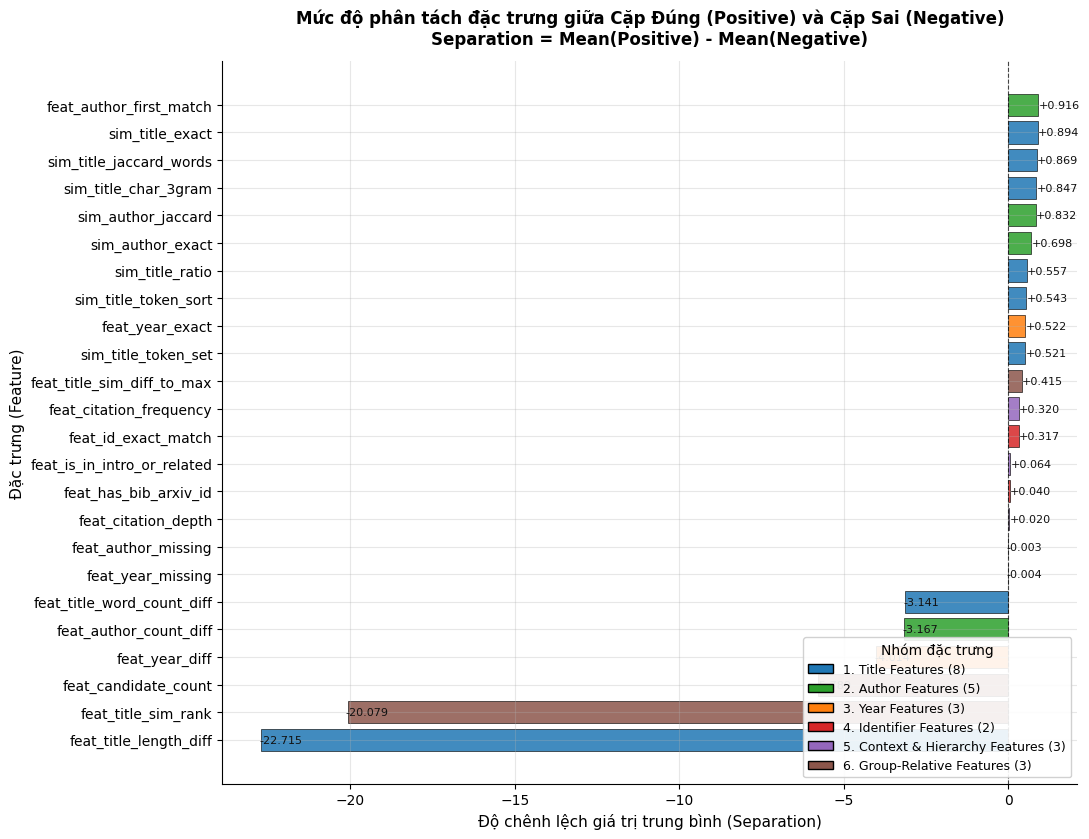

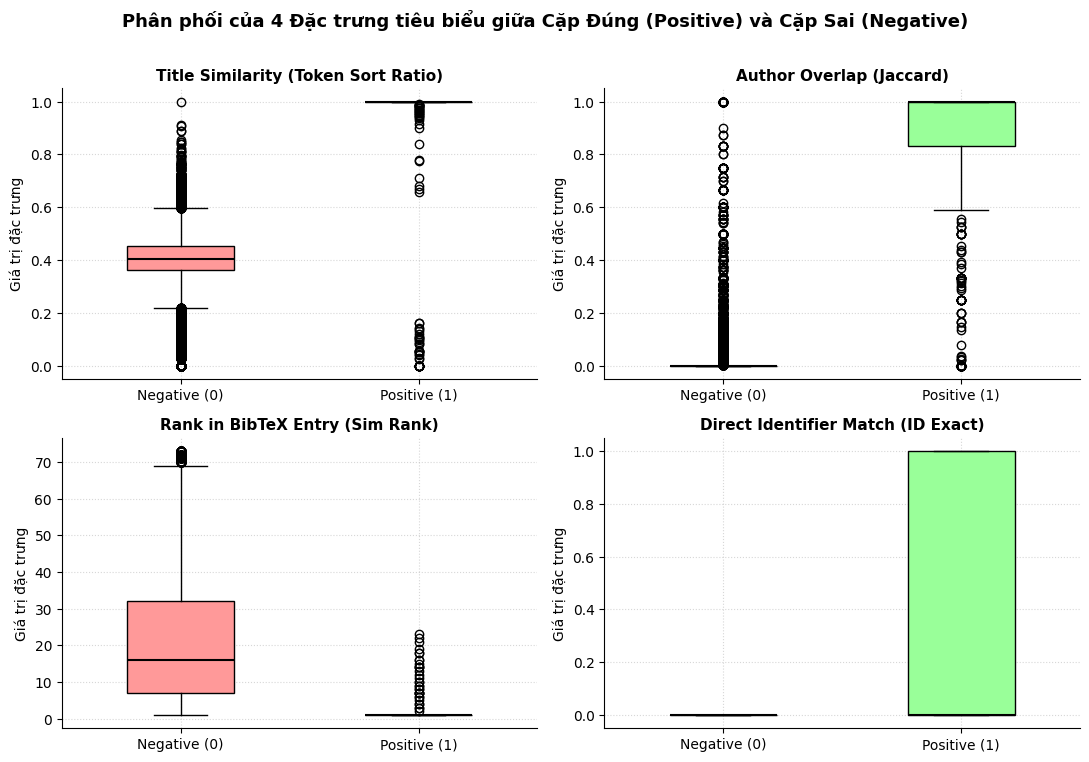

In [5]:
# 1. Biểu đồ thanh ngang (Horizontal Bar Chart) mức độ phân tách của cả 24 features
fig, ax = plt.subplots(figsize=(11, 8.5), dpi=100)

group_palette = {
    "1. Title Features (8)": "#1f77b4",
    "2. Author Features (5)": "#2ca02c",
    "3. Year Features (3)": "#ff7f0e",
    "4. Identifier Features (2)": "#d62728",
    "5. Context & Hierarchy Features (3)": "#9467bd",
    "6. Group-Relative Features (3)": "#8c564b",
}

plot_data = separation_table.sort_values(by="Separation (Diff)", ascending=True)
colors = [group_palette.get(g, "#333333") for g in plot_data["Group"]]

bars = ax.barh(plot_data.index, plot_data["Separation (Diff)"], color=colors, alpha=0.85, edgecolor="black", linewidth=0.5)
ax.axvline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.7)
ax.set_title("Mức độ phân tách đặc trưng giữa Cặp Đúng (Positive) và Cặp Sai (Negative)\nSeparation = Mean(Positive) - Mean(Negative)", fontsize=12, pad=12, fontweight="bold")
ax.set_xlabel("Độ chênh lệch giá trị trung bình (Separation)", fontsize=11)
ax.set_ylabel("Đặc trưng (Feature)", fontsize=11)

# Chú thích các nhóm đặc trưng
from matplotlib.patches import Patch
legend_handles = [Patch(facecolor=color, edgecolor="black", label=group) for group, color in group_palette.items()]
ax.legend(handles=legend_handles, title="Nhóm đặc trưng", loc="lower right", framealpha=0.9, fontsize=9)

# Ghi giá trị trên các thanh
for bar in bars:
    val = bar.get_width()
    offset = 0.01 if val >= 0 else -0.06
    ax.text(val + offset, bar.get_y() + bar.get_height() / 2, f"{val:+.3f}", va="center", fontsize=8, color="#111111")

plt.tight_layout()
plt.show()

# 2. Biểu đồ phân phối (Boxplots) cho 4 đặc trưng phân tách hàng đầu
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), dpi=100)
top_features = ["sim_title_token_sort", "sim_author_jaccard", "feat_title_sim_rank", "feat_id_exact_match"]
feature_titles = [
    "Title Similarity (Token Sort Ratio)",
    "Author Overlap (Jaccard)",
    "Rank in BibTeX Entry (Sim Rank)",
    "Direct Identifier Match (ID Exact)"
]

pos_data = matrix[matrix["label"] == 1.0]
neg_data = matrix[matrix["label"] == 0.0]

for idx, (feat, title) in enumerate(zip(top_features, feature_titles)):
    ax = axes[idx // 2, idx % 2]
    bp = ax.boxplot(
        [neg_data[feat].dropna(), pos_data[feat].dropna()],
        labels=["Negative (0)", "Positive (1)"],
        patch_artist=True,
        widths=0.45,
        medianprops=dict(color="black", linewidth=1.5)
    )
    bp["boxes"][0].set_facecolor("#ff9999")
    bp["boxes"][1].set_facecolor("#99ff99")
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_ylabel("Giá trị đặc trưng", fontsize=10)
    ax.grid(True, linestyle=":", alpha=0.5)

plt.suptitle("Phân phối của 4 Đặc trưng tiêu biểu giữa Cặp Đúng (Positive) và Cặp Sai (Negative)", fontsize=13, y=1.01, fontweight="bold")
plt.tight_layout()
plt.show()


## 6. Kết luận & Đóng góp vào Báo cáo Chung

1. **Về Auto-Labeling Pipeline:**
   - Đạt độ chính xác **Precision = 99.77%** và độ bao phủ **Recall = 94.26%** trên 20 bài manual pool (881 mục trích dẫn). Kết quả này khẳng định các bộ quy tắc Heuristic có độ tin cậy tuyệt đối, hoàn toàn loại bỏ rủi ro gán nhãn sai (label noise) khi tạo dữ liệu huấn luyện mở rộng.
   - Kết quả kiểm định chi tiết đã được đồng bộ lưu trữ tại `data/matching/auto_label_validation.json`.

2. **Về Feature Engineering:**
   - Xây dựng thành công **6 nhóm với 24 đặc trưng** đa chiều, phản ánh đầy đủ thông tin từ cú pháp tiêu đề, tác giả, năm, định danh arXiv đến ngữ cảnh vị trí trích dẫn trong cây phân cấp Milestone 2 (`feat_citation_depth`, `feat_citation_frequency`, `feat_is_in_intro_or_related`).
   - Phân tích phân tách cho thấy nhóm **Title Features** (`sim_title_token_sort`, `sim_title_ratio`) và **Group-Relative Features** (`feat_title_sim_rank`, `feat_title_sim_diff_to_max`) có khả năng phân biệt cực mạnh giữa cặp đúng và cặp nhiễu.
   - Nhóm **Author Features** (`sim_author_jaccard`, `feat_author_first_match`) và **Identifier Features** (`feat_id_exact_match`) đóng vai trò là các tín hiệu xác thực bổ trợ quan trọng.

3. **Bàn giao cho Modeling & Poster:**
   - Toàn bộ ma trận ứng viên `candidate_matrix.parquet` (34,377 cặp) đã được bàn giao sẵn sàng cho bạn Tân huấn luyện các mô hình Logistic Regression, LightGBM và Ranking.
   - Các biểu đồ phân tách và bảng chỉ số đã sẵn sàng để đưa vào slide thuyết trình và Poster A2 của nhóm.
